# 기능 C 냥기사 LoRA 학습 데이터 장수별 비교 (10/27)

06 "학습 시간과 장수별 실험 일정"에서 정한 장수별 실험이다. 06의 설정·함수를 이 노트북 안에 다시 넣었다(값은 06과 같다).

- 목적: 그림체 LoRA에 학습 이미지가 몇 장 필요한지 확인한다. 소상공인(1인 개발자)이 직접 모을 수 있는 장수인지가 기준이다.
- 캡션은 트리거 단어(`nyang_knight_style`) 캡션만 쓴다. 06에서 NAI 프롬프트 캡션은 생성할 때 그림체 태그를 같이 넣어야 해서, 트리거 캡션 조합만 후보로 남겼다(10/22).
- 학습 체크포인트 후보 2개(Animagine XL 4.0 Zero, 4.0)를 모두 학습하고, 적용 조합 3개를 모두 평가한다.

| 적용 조합 | 06 결과 (trigger, 1,600스텝, `lora_eval_summary.csv`) |
|---|---|
| Zero에서 학습 → Zero에 적용 | style_sim 0.740~0.757 (스텝별) |
| Zero에서 학습 → 4.0에 적용 | 0.745~0.756 |
| 4.0에서 학습 → 4.0에 적용 | 0.716~0.745 |

- 장수: 50 · 100 · 200 · 400장을 새로 학습하고, 800장은 06의 `zero_trigger`·`v40_trigger` 학습 결과와 평가 이미지를 그대로 쓴다(같은 설정·같은 seed).
- 부분집합: 800장에서 카테고리(주인공·배경·스크린샷·동료·아이템) 비율을 유지해 뽑고, 작은 집합이 큰 집합에 포함되게 한다(50 ⊂ 100 ⊂ 200 ⊂ 400 ⊂ 800). 장수 외에 그림 구성이 바뀌지 않게 하려는 것이다.
- 학습 설정: 06과 같다(rank 4, 학습률 1e-4, 배치 1, 1024, 총 1,600스텝 고정, 400스텝마다 저장, fp16, seed 42). 총 스텝 고정은 06에서 정한 기준이다. 50장은 32에폭, 400장은 4에폭이 된다.
- 평가: 06과 같다(주인공 고정 태그 + 학습 데이터에 없는 장면 문구 4개 + 트리거 단어, Euler Ancestral 28스텝, CFG 5, 1024×1024, seed 0·1). 점수는 06과 같은 CLIP으로 그림체 점수(`style_sim`, 원본 NAI 17장과의 유사도)와 장면 반영 점수(`scene_sim`, `scene_top1`)를 함께 잰다.
- 기록 (`outputs/lora_sweep/`)
  - `sweep_config.json`: 실험 조건(장수, 체크포인트, 적용 조합, 평가 스텝, 학습 설정, 부분집합 카테고리별 장수), 패키지 버전, GPU
  - `subsets.csv`: 장수별로 뽑힌 파일 목록
  - `train_runs.csv`, `logs/`: 학습 1회마다 소요 시간, 스텝당 시간, 최대 GPU 메모리, 종료 코드, 학습 로그
  - `lora_eval.csv`: 평가 이미지 1장마다 조합·스텝·문구·seed·생성 시간
  - `lora_eval_scored.csv`, `lora_eval_summary.csv`, `sweep_data.png`, `sweep_train_time.png`, `sweep_scores.png`, `sweep_grid.png`
- 실행 순서: 위에서부터 차례로 실행한다. 중간에 멈춰도 다시 실행하면 끝난 학습·이미지는 건너뛴다.
- 예상 시간: 설정 셀 출력에 06 기록 기준으로 계산해 보여준다(학습 8회 × 약 0.49시간 + 평가 이미지 384장 × 약 11초 ≈ 5시간). 학습 체크포인트나 평가 스텝을 줄이려면 설정 셀의 `TRAIN_CKPTS`, `EVAL_STEPS`를 바꾼다.
- GPU를 다른 노트북(10 등)과 동시에 쓰지 않는다.

## 설정

In [1]:
import gc
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import threading
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path('..')
NAI_DIR = ROOT / 'data' / 'raw' / 'nai'
GEN_DIR = NAI_DIR / 'lora_gen'
DATA_DIR = ROOT / 'data' / 'processed' / 'nai_lora'
SWEEP_DATA = DATA_DIR / 'sweep'
LORA_DIR = ROOT / 'models' / 'lora'
SWEEP_LORA = LORA_DIR / 'sweep'
OUT06 = ROOT / 'outputs' / 'lora_train'
OUT_DIR = ROOT / 'outputs' / 'lora_sweep'
SCRIPT = ROOT / 'src' / 'train' / 'train_text_to_image_lora_sdxl.py'
for d in [SWEEP_DATA, SWEEP_LORA, OUT_DIR]:
    d.mkdir(parents=True, exist_ok=True)
assert SCRIPT.exists(), '학습 스크립트가 없음 → 06 "학습 스크립트 확보" 셀을 먼저 실행'

# 06 설정과 같은 값
DIFFUSERS_COMMIT = 'efe46a5b177af67c64b3666da8ddddac7ee12163'
CKPTS = {
    'v40': 'cagliostrolab/animagine-xl-4.0',
    'zero': 'cagliostrolab/animagine-xl-4.0-zero',
}
VAE = 'madebyollin/sdxl-vae-fp16-fix'
TRIGGER = 'nyang_knight_style'
CAP = 'trigger'
TRAIN = dict(resolution=1024, train_batch_size=1, max_train_steps=1600, checkpointing_steps=400,
             learning_rate=1e-4, lr_scheduler='constant', lr_warmup_steps=0, rank=4,
             mixed_precision='fp16', seed=42)
# 06 "평가 이미지 생성"과 같은 평가 설정
CAT = ('no humans, black cat adventurer, yellow eyes, red wide-brim hat, ears through headwear, olive green capelet, '
       'brown cross-shaped clasp, brown belt, short sword at hip, olive green cape with shield emblem')
EVAL_PHRASES = ['sailing a small boat', 'lake at sunset', 'busy market stall', 'snowy mountain village']
EVAL_SEEDS = [0, 1]

# 이 실험의 조건
FULL_SIZE = 800                      # 06에서 학습한 장수 (06 결과를 그대로 씀)
SWEEP_SIZES = [50, 100, 200, 400]    # 06 SWEEP_SIZES에서 800을 뺀 장수 (새로 학습)
SUBSET_SEED = 0
TRAIN_CKPTS = ['zero', 'v40']        # 학습 체크포인트 후보 2개 모두
APPLY = [('zero', 'zero'), ('v40', 'zero'), ('v40', 'v40')]  # (적용 체크포인트, 학습 체크포인트)
EVAL_STEPS = [400, 800, 1200, 1600]  # 06과 같은 저장 시점 전부
APPLY_NAME = {('zero', 'zero'): 'LoRA(Zero) on Zero', ('v40', 'zero'): 'LoRA(Zero) on 4.0', ('v40', 'v40'): 'LoRA(4.0) on 4.0'}

# 예상 시간 (06 기록 기준)
r06 = pd.read_csv(OUT06 / 'train_runs.csv')
r06 = r06[(r06.returncode == 0) & (r06.caption == CAP)]
e06 = pd.read_csv(OUT06 / 'lora_eval.csv', keep_default_na=False)
e06_lora_sec = e06[e06.train_ckpt != ''].sec.mean()
n_train = len(SWEEP_SIZES) * len(TRAIN_CKPTS)
n_eval = len(SWEEP_SIZES) * len(EVAL_STEPS) * len(APPLY) * len(EVAL_PHRASES) * len(EVAL_SEEDS)
h_train = n_train * r06.sec.mean() / 3600
h_eval = n_eval * e06_lora_sec / 3600
print(f'학습 {n_train}회 × {r06.sec.mean() / 3600:.2f}시간 (06 trigger 학습 평균) = {h_train:.1f}시간')
print(f'평가 이미지 {n_eval}장 × {e06_lora_sec:.1f}초 (06 LoRA 평가 평균) = {h_eval:.1f}시간')
print(f'합계 약 {h_train + h_eval:.1f}시간 (모델 로드 시간 제외)')

학습 8회 × 0.48시간 (06 trigger 학습 평균) = 3.9시간
평가 이미지 384장 × 10.7초 (06 LoRA 평가 평균) = 1.1시간
합계 약 5.0시간 (모델 로드 시간 제외)


## 장수별 학습 데이터 (부분집합)

,50,100,200,400,800
category,,,,,
protagonist,15,30,60,120,240
background,10,20,40,80,160
screenshot,5,10,20,40,80
dog,5,9,18,35,70
owl,4,9,18,35,70
rabbit,4,9,17,35,70
slime,4,8,17,35,70
item,3,5,10,20,40


50 ..\data\processed\nai_lora\sweep\trigger_n50 이미지 50
100 ..\data\processed\nai_lora\sweep\trigger_n100 이미지 100
200 ..\data\processed\nai_lora\sweep\trigger_n200 이미지 200
400 ..\data\processed\nai_lora\sweep\trigger_n400 이미지 400
설정 기록: sweep_config.json | GPU: NVIDIA GeForce RTX 3090, 24576 MiB, 610.88 | diffusers 0.41.0.dev0


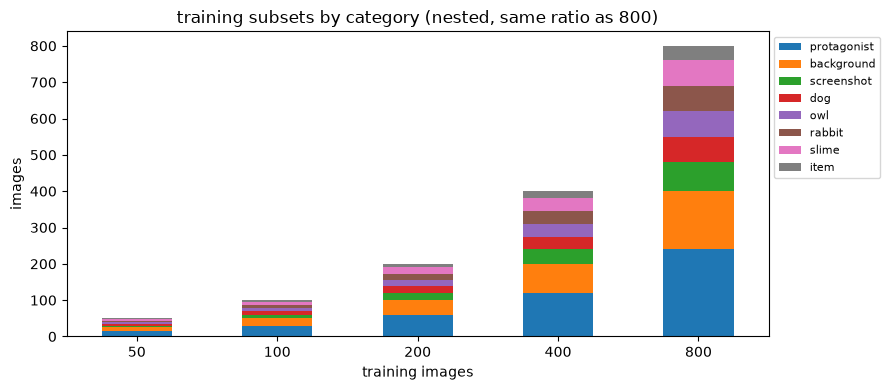

In [2]:
meta = pd.read_json(DATA_DIR / CAP / 'metadata.jsonl', lines=True)
cats_of = pd.read_csv(GEN_DIR / 'prompts.csv', encoding='utf-8-sig').set_index('file').category
meta['category'] = meta.file_name.map(cats_of)
assert len(meta) == FULL_SIZE and meta.category.notna().all(), '06 데이터 준비 결과(800장)와 다름'
assert meta.text.str.endswith(TRIGGER).all()

# 카테고리 안에서 무작위 순위를 한 번 정하고, 장수마다 순위 앞쪽부터 뽑음 → 작은 집합이 큰 집합에 포함됨
rng = np.random.default_rng(SUBSET_SEED)
meta['rank'] = -1
for cat in sorted(meta.category.unique()):
    idx = meta.index[meta.category == cat]
    meta.loc[idx, 'rank'] = rng.permutation(len(idx))
cats = meta.category.value_counts().sort_index().sort_values(ascending=False, kind='stable')


def alloc(size):
    # 카테고리 비율대로 나누고, 남는 장수는 소수점 아래가 큰 카테고리부터 1장씩
    q = cats / cats.sum() * size
    k = np.floor(q).astype(int)
    k[(q - k).sort_values(ascending=False, kind='stable').index[:size - k.sum()]] += 1
    return k


alloc_tab = pd.DataFrame({s: alloc(s) for s in SWEEP_SIZES + [FULL_SIZE]})
assert (alloc_tab.sum() == alloc_tab.columns).all()
assert (alloc_tab.diff(axis=1).fillna(0) >= 0).all().all(), '작은 집합이 큰 집합에 포함되지 않음'
display(alloc_tab)

sub_rows = []
for size in SWEEP_SIZES:
    sel = meta[meta['rank'] < meta.category.map(alloc_tab[size])]
    d = SWEEP_DATA / f'{CAP}_n{size}'
    d.mkdir(parents=True, exist_ok=True)
    with open(d / 'metadata.jsonl', 'w', encoding='utf-8') as f:
        for _, r in sel.iterrows():
            dst = d / r.file_name
            if not dst.exists():
                try:
                    os.link(DATA_DIR / CAP / r.file_name, dst)
                except OSError:
                    shutil.copy2(DATA_DIR / CAP / r.file_name, dst)
            f.write(json.dumps({'file_name': r.file_name, 'text': r.text}, ensure_ascii=False) + '\n')
    pngs = {p.name for p in d.glob('*.png')}
    assert pngs == set(sel.file_name), f'{d}에 부분집합 밖의 이미지가 있음'
    sub_rows += [dict(size=size, file=r.file_name, category=r.category) for _, r in sel.iterrows()]
    print(size, d, '이미지', len(pngs))
subsets = pd.DataFrame(sub_rows)
subsets.to_csv(OUT_DIR / 'subsets.csv', index=False, encoding='utf-8-sig')
for a, b in zip(SWEEP_SIZES, SWEEP_SIZES[1:]):
    assert set(subsets[subsets['size'] == a].file) <= set(subsets[subsets['size'] == b].file)


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 보고서용 실험 설정 기록
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), sizes_new=SWEEP_SIZES, size_reused=FULL_SIZE, subset_seed=SUBSET_SEED,
    subset_rule='카테고리 비율 유지(최대 나머지 방식), 카테고리 안 무작위 순위로 포함 관계 유지',
    subset_counts={str(s): alloc_tab[s].to_dict() for s in alloc_tab.columns}, caption=CAP, trigger=TRIGGER,
    train_ckpts={c: CKPTS[c] for c in TRAIN_CKPTS}, vae=VAE, train=TRAIN, train_script=str(SCRIPT),
    diffusers_commit=DIFFUSERS_COMMIT, apply=[dict(apply=a, train=t, name=APPLY_NAME[(a, t)]) for a, t in APPLY],
    eval=dict(steps=EVAL_STEPS, phrases=EVAL_PHRASES, seeds=EVAL_SEEDS, cat=CAT, scheduler='EulerAncestral',
              num_inference_steps=28, guidance_scale=5.0, size=1024, prompt_form='CAT, phrase, TRIGGER'),
    reused_from_06=dict(lora=[f'{c}_{CAP}' for c in TRAIN_CKPTS], eval_csv=str(OUT06 / 'lora_eval.csv')),
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'peft', 'accelerate', 'datasets',
                                          'pillow', 'pandas', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
(OUT_DIR / 'sweep_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
print('설정 기록: sweep_config.json | GPU:', config['gpu'], '| diffusers', config['versions']['diffusers'])

ax = alloc_tab.T.plot.bar(stacked=True, figsize=(9, 4), rot=0)
ax.set_xlabel('training images')
ax.set_ylabel('images')
ax.set_title('training subsets by category (nested, same ratio as 800)')
ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(OUT_DIR / 'sweep_data.png', dpi=90)
plt.show()

## 학습 실행 함수 (06과 같음)

In [3]:
LOG_DIR = OUT_DIR / 'logs'
LOG_DIR.mkdir(exist_ok=True)
RUNS_CSV = OUT_DIR / 'train_runs.csv'


def gpu_used_mb():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=memory.used', '--format=csv,noheader,nounits'],
                             capture_output=True, text=True, timeout=10).stdout
        return int(out.strip().splitlines()[0])
    except Exception:
        return None


# 06 train()과 같고, 학습 데이터 폴더와 저장 폴더만 장수별로 바뀜
def train(ckpt, size):
    run = f'{ckpt}_{CAP}_n{size}'
    out = SWEEP_LORA / run
    if (out / 'pytorch_lora_weights.safetensors').exists():
        print(run, '이미 학습됨 → 건너뜀')
        return None
    args = {**TRAIN, 'pretrained_model_name_or_path': CKPTS[ckpt], 'pretrained_vae_model_name_or_path': VAE,
            'train_data_dir': str((SWEEP_DATA / f'{CAP}_n{size}').resolve()), 'image_column': 'image',
            'caption_column': 'text', 'output_dir': str(out.resolve()), 'report_to': 'tensorboard'}
    cmd = [sys.executable, str(SCRIPT.resolve())] + [f'--{k}={v}' for k, v in args.items()]
    peak, stop = [0], threading.Event()

    def watch():
        while not stop.wait(2):
            v = gpu_used_mb()
            if v:
                peak[0] = max(peak[0], v)

    threading.Thread(target=watch, daemon=True).start()
    base_mb = gpu_used_mb()
    started = time.strftime('%Y-%m-%d %H:%M:%S')
    t0 = time.perf_counter()
    with open(LOG_DIR / f'{run}.log', 'w', encoding='utf-8') as log:
        p = subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT, env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    sec = round(time.perf_counter() - t0, 1)
    stop.set()
    steps = TRAIN['max_train_steps']
    rec = dict(run=run, ckpt=ckpt, caption=CAP, size=size, epochs=round(steps * TRAIN['train_batch_size'] / size, 2),
               steps=steps, returncode=p.returncode, sec=sec, sec_per_step=round(sec / steps, 3),
               peak_gpu_mb=peak[0] or None, gpu_mb_before=base_mb, started=started,
               finished=time.strftime('%Y-%m-%d %H:%M:%S'))
    pd.DataFrame([rec]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8')
    print(rec, flush=True)
    if p.returncode != 0:
        print(''.join(open(LOG_DIR / f'{run}.log', encoding='utf-8', errors='replace').readlines()[-40:]))
    return rec

## 학습 (장수 4개 × 학습 체크포인트 2개)

작은 장수부터 학습한다. 각 학습은 400스텝마다 `checkpoint-400`·`-800`·`-1200`·`-1600`을 저장한다.

{'run': 'zero_trigger_n50', 'ckpt': 'zero', 'caption': 'trigger', 'size': 50, 'epochs': 32.0, 'steps': 1600, 'returncode': 0, 'sec': 1902.9, 'sec_per_step': 1.189, 'peak_gpu_mb': 18138, 'gpu_mb_before': 2990, 'started': '2026-10-27 14:11:17', 'finished': '2026-10-27 14:43:00'}
{'run': 'v40_trigger_n50', 'ckpt': 'v40', 'caption': 'trigger', 'size': 50, 'epochs': 32.0, 'steps': 1600, 'returncode': 0, 'sec': 1660.5, 'sec_per_step': 1.038, 'peak_gpu_mb': 17332, 'gpu_mb_before': 1958, 'started': '2026-10-27 14:43:00', 'finished': '2026-10-27 15:10:41'}
{'run': 'zero_trigger_n100', 'ckpt': 'zero', 'caption': 'trigger', 'size': 100, 'epochs': 16.0, 'steps': 1600, 'returncode': 0, 'sec': 1710.8, 'sec_per_step': 1.069, 'peak_gpu_mb': 17515, 'gpu_mb_before': 2293, 'started': '2026-10-27 15:10:41', 'finished': '2026-10-27 15:39:12'}
{'run': 'v40_trigger_n100', 'ckpt': 'v40', 'caption': 'trigger', 'size': 100, 'epochs': 16.0, 'steps': 1600, 'returncode': 0, 'sec': 1709.5, 'sec_per_step': 1.068, 'p

,run,ckpt,size,epochs,steps,sec,hours,sec_per_step,peak_gpu_mb
0,zero_trigger_n50,zero,50,32.0,1600,1902.9,0.529,1.189,18138
1,v40_trigger_n50,v40,50,32.0,1600,1660.5,0.461,1.038,17332
2,zero_trigger_n100,zero,100,16.0,1600,1710.8,0.475,1.069,17515
3,v40_trigger_n100,v40,100,16.0,1600,1709.5,0.475,1.068,17384
4,zero_trigger_n200,zero,200,8.0,1600,1702.6,0.473,1.064,17720
5,v40_trigger_n200,v40,200,8.0,1600,1696.7,0.471,1.060,18014
6,zero_trigger_n400,zero,400,4.0,1600,1758.9,0.489,1.099,18672
7,v40_trigger_n400,v40,400,4.0,1600,1699.5,0.472,1.062,17295
8,v40_trigger,v40,800,2.0,1600,1765.4,0.490,1.103,18607
9,zero_trigger,zero,800,2.0,1600,1706.4,0.474,1.067,18638


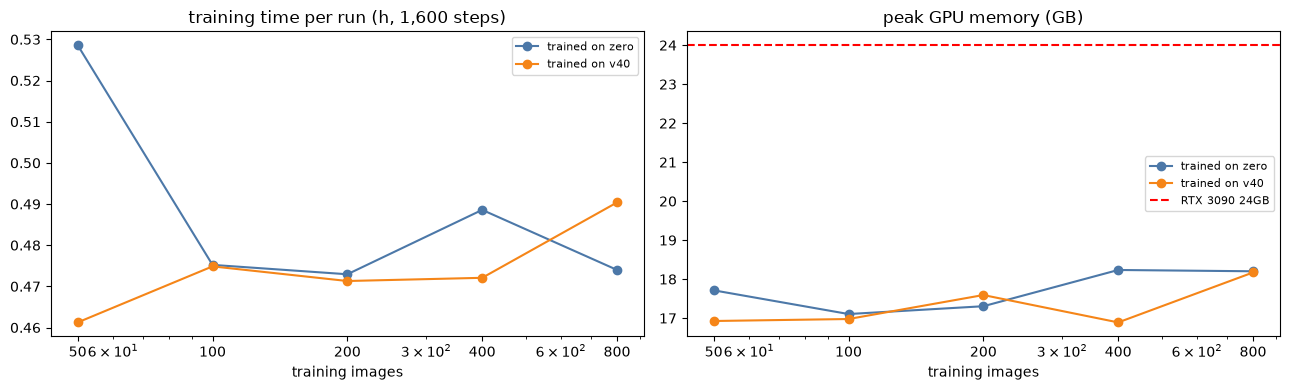

In [4]:
for size in SWEEP_SIZES:
    for ckpt in TRAIN_CKPTS:
        rec = train(ckpt, size)
        if rec and rec['returncode'] != 0:
            raise RuntimeError(f"{rec['run']} 학습 실패 → 위 로그 확인 (outputs/lora_sweep/logs)")

runs = pd.read_csv(RUNS_CSV)
runs = runs[runs.returncode == 0].drop_duplicates('run', keep='last')
# 800장은 06 학습 기록
prev = r06[r06.ckpt.isin(TRAIN_CKPTS)].assign(size=FULL_SIZE, epochs=TRAIN['max_train_steps'] / FULL_SIZE)
runs_all = pd.concat([runs, prev], ignore_index=True)
runs_all['hours'] = runs_all.sec / 3600
display(runs_all[['run', 'ckpt', 'size', 'epochs', 'steps', 'sec', 'hours', 'sec_per_step', 'peak_gpu_mb']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for c, color in zip(TRAIN_CKPTS, ['#4C78A8', '#F58518']):
    s = runs_all[runs_all.ckpt == c].sort_values('size')
    axes[0].plot(s['size'], s.hours, marker='o', color=color, label=f'trained on {c}')
    axes[1].plot(s['size'], s.peak_gpu_mb / 1024, marker='o', color=color, label=f'trained on {c}')
axes[1].axhline(24, color='red', linestyle='--', label='RTX 3090 24GB')
for ax, title in zip(axes, ['training time per run (h, 1,600 steps)', 'peak GPU memory (GB)']):
    ax.set_xscale('log')
    ax.set_xticks(SWEEP_SIZES + [FULL_SIZE], [str(s) for s in SWEEP_SIZES + [FULL_SIZE]])
    ax.set_xlabel('training images')
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'sweep_train_time.png', dpi=90)
plt.show()

## 평가 이미지 생성 (06과 같은 설정)

In [5]:
import torch
from diffusers import AutoencoderKL, EulerAncestralDiscreteScheduler, StableDiffusionXLPipeline

EVAL_DIR = OUT_DIR / 'eval'
EVAL_DIR.mkdir(exist_ok=True)
EVAL_CSV = OUT_DIR / 'lora_eval.csv'


def eval_prompt(phrase):
    return f'{CAT}, {phrase}, {TRIGGER}'


def lora_path(train_ckpt, size, step):
    run_dir = LORA_DIR / f'{train_ckpt}_{CAP}' if size == FULL_SIZE else SWEEP_LORA / f'{train_ckpt}_{CAP}_n{size}'
    return run_dir / f'checkpoint-{step}'


def combo_name(apply, train_ckpt, size, step):
    return f'{apply}__lora-{train_ckpt}-n{size}-s{step}'


COMBOS = [(a, t, size, step) for size in SWEEP_SIZES for step in EVAL_STEPS for a, t in APPLY if t in TRAIN_CKPTS]
done = set(pd.read_csv(EVAL_CSV).file) if EVAL_CSV.exists() else set()
vae = AutoencoderKL.from_pretrained(VAE, torch_dtype=torch.float16)
for apply in sorted({c[0] for c in COMBOS}):
    todo = [c for c in COMBOS if c[0] == apply]
    t_load = time.perf_counter()
    pipe = StableDiffusionXLPipeline.from_pretrained(CKPTS[apply], vae=vae, torch_dtype=torch.float16).to('cuda')
    pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    print(apply, '모델 로드', round(time.perf_counter() - t_load, 1), '초', flush=True)
    for _, train_ckpt, size, step in todo:
        name = combo_name(apply, train_ckpt, size, step)
        files = {(ph, s): f'{name}__p{i}_s{s}.png' for i, ph in enumerate(EVAL_PHRASES) for s in EVAL_SEEDS}
        if all(f in done for f in files.values()):
            continue
        lp = lora_path(train_ckpt, size, step)
        if not (lp / 'pytorch_lora_weights.safetensors').exists():
            print('LoRA 없음 → 건너뜀', lp)
            continue
        pipe.load_lora_weights(str(lp), weight_name='pytorch_lora_weights.safetensors', adapter_name='style')
        for (ph, s), f in files.items():
            if f in done:
                continue
            t0 = time.perf_counter()
            img = pipe(prompt=eval_prompt(ph), num_inference_steps=28, guidance_scale=5.0, width=1024, height=1024,
                       generator=torch.Generator('cpu').manual_seed(s)).images[0]
            sec = round(time.perf_counter() - t0, 2)
            img.save(EVAL_DIR / f)
            rec = dict(file=f, combo=name, apply=apply, train_ckpt=train_ckpt, caption=CAP, size=size, step=step,
                       phrase=ph, seed=s, sec=sec, lora=str(lp), finished=time.strftime('%Y-%m-%d %H:%M:%S'))
            pd.DataFrame([rec]).to_csv(EVAL_CSV, mode='a', header=not EVAL_CSV.exists(), index=False, encoding='utf-8')
            done.add(f)
        print(name, 'done', flush=True)
        pipe.unload_lora_weights()
    del pipe
    gc.collect()
    torch.cuda.empty_cache()
print('평가 이미지', len(done), '장 (이 노트북에서 생성)')

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Multiple distributions found for package optimum. Picked distribution: optimum
W1027 18:02:14.590000 34448 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1027 18:02:14.680000 34448 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading 

v40 모델 로드 5.5 초

INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True,max_split_size_mb:256,garbage_collection_threshold:0.7' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO  

┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐
│ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │
└─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘
GPT-QModel   : 7.3.4
Transformers : 5.20.1
Torch        : 2.14.1+cu130
Triton       : 3.7.1.post27


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
100%|██████████| 28/28 [00:10<00:00,  2.79it/s]


v40__lora-zero-n50-s400 done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
100%|██████████| 28/28 [00:10<00:00,  2.78it/s]


v40__lora-v40-n50-s400 done


... (90 outputs left out)

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
100%|██████████| 28/28 [00:09<00:00,  2.94it/s]


zero__lora-zero-n400-s1200 done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModelWithProjection found with the prefix='text_encoder_2'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModelWithProjection related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
100%|██████████| 28/28 [00:09<00:00,  2.97it/s]


zero__lora-zero-n400-s1600 done
평가 이미지 384 장 (이 노트북에서 생성)


## 그림체 점수·장면 반영 점수

In [6]:
import torch
from transformers import CLIPModel, CLIPProcessor

# 06과 같은 CLIP
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def feat(out):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    return out.pooler_output if hasattr(out, 'pooler_output') else out


def unit(e):
    e = feat(e).float().cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


def embed(paths, bs=16):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), bs):
            x = clip_proc(images=[Image.open(p).convert('RGB') for p in paths[i:i + bs]], return_tensors='pt').to('cuda')
            out.append(unit(clip.get_image_features(**x)))
    return np.concatenate(out)


# 이 노트북의 평가 이미지 + 06의 800장·LoRA 없음 평가 이미지(같은 프롬프트·seed)
assert EVAL_CSV.exists(), '평가 이미지가 없음 → 위 "평가 이미지 생성" 셀 출력 확인'
ev_new = pd.read_csv(EVAL_CSV, keep_default_na=False).drop_duplicates('file', keep='last')
ev_new['path'] = [str(EVAL_DIR / f) for f in ev_new.file]
ev_new['source'] = 'this notebook'
e06 = pd.read_csv(OUT06 / 'lora_eval.csv', keep_default_na=False).drop_duplicates('file', keep='last')
keep = np.array([(a, t) in APPLY and t in TRAIN_CKPTS for a, t in zip(e06['apply'], e06.train_ckpt)])
e06 = e06[(e06.train_ckpt == '') | ((e06.caption == CAP) & e06.step.isin(EVAL_STEPS) & keep)]
e06 = e06.assign(size=np.where(e06.train_ckpt == '', 0, FULL_SIZE), path=[str(OUT06 / 'eval' / f) for f in e06.file],
                 source='06')
ev = pd.concat([ev_new, e06], ignore_index=True)
print('평가 이미지:', ev.groupby('source').size().to_dict())

orig = sorted(NAI_DIR.glob('*.png'))
ORIG_EMB = embed(orig)
orig_base = float((ORIG_EMB @ ORIG_EMB.T)[~np.eye(len(orig), dtype=bool)].mean())
print('원본', len(orig), '장 | 원본끼리 평균 유사도(기준선):', round(orig_base, 3))
E = embed(list(ev.path))
ev['style_sim'] = (E @ ORIG_EMB.T).mean(1)
with torch.no_grad():
    t = clip_proc(text=EVAL_PHRASES, return_tensors='pt', padding=True).to('cuda')
    T = unit(clip.get_text_features(**t))
S = E @ T.T
idx = ev.phrase.map(EVAL_PHRASES.index).values
ev['scene_sim'] = S[np.arange(len(ev)), idx]
ev['scene_top1'] = S.argmax(1) == idx
ev['label'] = [f'{a} no LoRA' if t == '' else APPLY_NAME[(a, t)] for a, t in zip(ev['apply'], ev.train_ckpt)]
ev.drop(columns=['path']).to_csv(OUT_DIR / 'lora_eval_scored.csv', index=False, encoding='utf-8-sig')
summary = ev.groupby(['label', 'apply', 'train_ckpt', 'size', 'step'], sort=False).agg(
    style_sim=('style_sim', 'mean'), style_std=('style_sim', 'std'), scene_sim=('scene_sim', 'mean'),
    scene_std=('scene_sim', 'std'), scene_top1=('scene_top1', 'mean'), n=('file', 'size'), sec=('sec', 'mean')).reset_index()
summary = summary.sort_values(['label', 'size', 'step'])
summary.to_csv(OUT_DIR / 'lora_eval_summary.csv', index=False, encoding='utf-8-sig')
pd.set_option('display.max_rows', 200)
display(summary.round(4))
print('조합·장수별 마지막 스텝(1,600)')
display(summary[summary.step == max(EVAL_STEPS)].pivot_table(index='label', columns='size', values=['style_sim', 'scene_sim']).round(4))

INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/revision/main "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/main/model.safetensors "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32 "HTTP/1.1 200 OK"
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19843.72it/s]
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/commits/main "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/discussions?p=0 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-base-patch32/commits/refs%2Fpr%2F66 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-base-patch32/resolve/refs%2Fpr%2F66/model.safetensors.index.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP R

평가 이미지: {'06': 112, 'this notebook': 384}
원본 17 장 | 원본끼리 평균 유사도(기준선): 0.687


,label,apply,train_ckpt,size,step,style_sim,style_std,scene_sim,scene_std,scene_top1,n,sec
1,LoRA(4.0) on 4.0,v40,v40,50,400,0.7416,0.0122,0.1830,0.0216,0.500,8,10.5012
3,LoRA(4.0) on 4.0,v40,v40,50,800,0.7423,0.0194,0.1920,0.0385,0.500,8,10.4875
5,LoRA(4.0) on 4.0,v40,v40,50,1200,0.7401,0.0166,0.1991,0.0364,0.500,8,10.5238
7,LoRA(4.0) on 4.0,v40,v40,50,1600,0.7473,0.0162,0.2013,0.0430,0.375,8,10.5188
9,LoRA(4.0) on 4.0,v40,v40,100,400,0.7276,0.0162,0.1982,0.0415,0.625,8,10.5300
11,LoRA(4.0) on 4.0,v40,v40,100,800,0.7508,0.0077,0.2013,0.0348,0.500,8,10.5038
13,LoRA(4.0) on 4.0,v40,v40,100,1200,0.7466,0.0198,0.1997,0.0210,0.500,8,10.5088
15,LoRA(4.0) on 4.0,v40,v40,100,1600,0.7478,0.0130,0.2085,0.0325,0.500,8,10.4950
17,LoRA(4.0) on 4.0,v40,v40,200,400,0.7327,0.0136,0.1920,0.0423,0.500,8,10.4788
19,LoRA(4.0) on 4.0,v40,v40,200,800,0.7419,0.0076,0.1924,0.0304,0.500,8,10.4950


조합·장수별 마지막 스텝(1,600)


scene_sim                                 style_sim  \
size                     50      100     200     400     800       50    
label                                                                    
LoRA(4.0) on 4.0      0.2013  0.2085  0.1965  0.2057  0.1948    0.7473   
LoRA(Zero) on 4.0     0.2026  0.1981  0.1898  0.1995  0.1872    0.7550   
LoRA(Zero) on Zero    0.2029  0.2054  0.1959  0.2062  0.2004    0.7552   

                                                    
size                   100     200     400     800  
label                                               
LoRA(4.0) on 4.0    0.7478  0.7488  0.7420  0.7409  
LoRA(Zero) on 4.0   0.7534  0.7542  0.7596  0.7560  
LoRA(Zero) on Zero  0.7501  0.7567  0.7505  0.7531

## 시각화

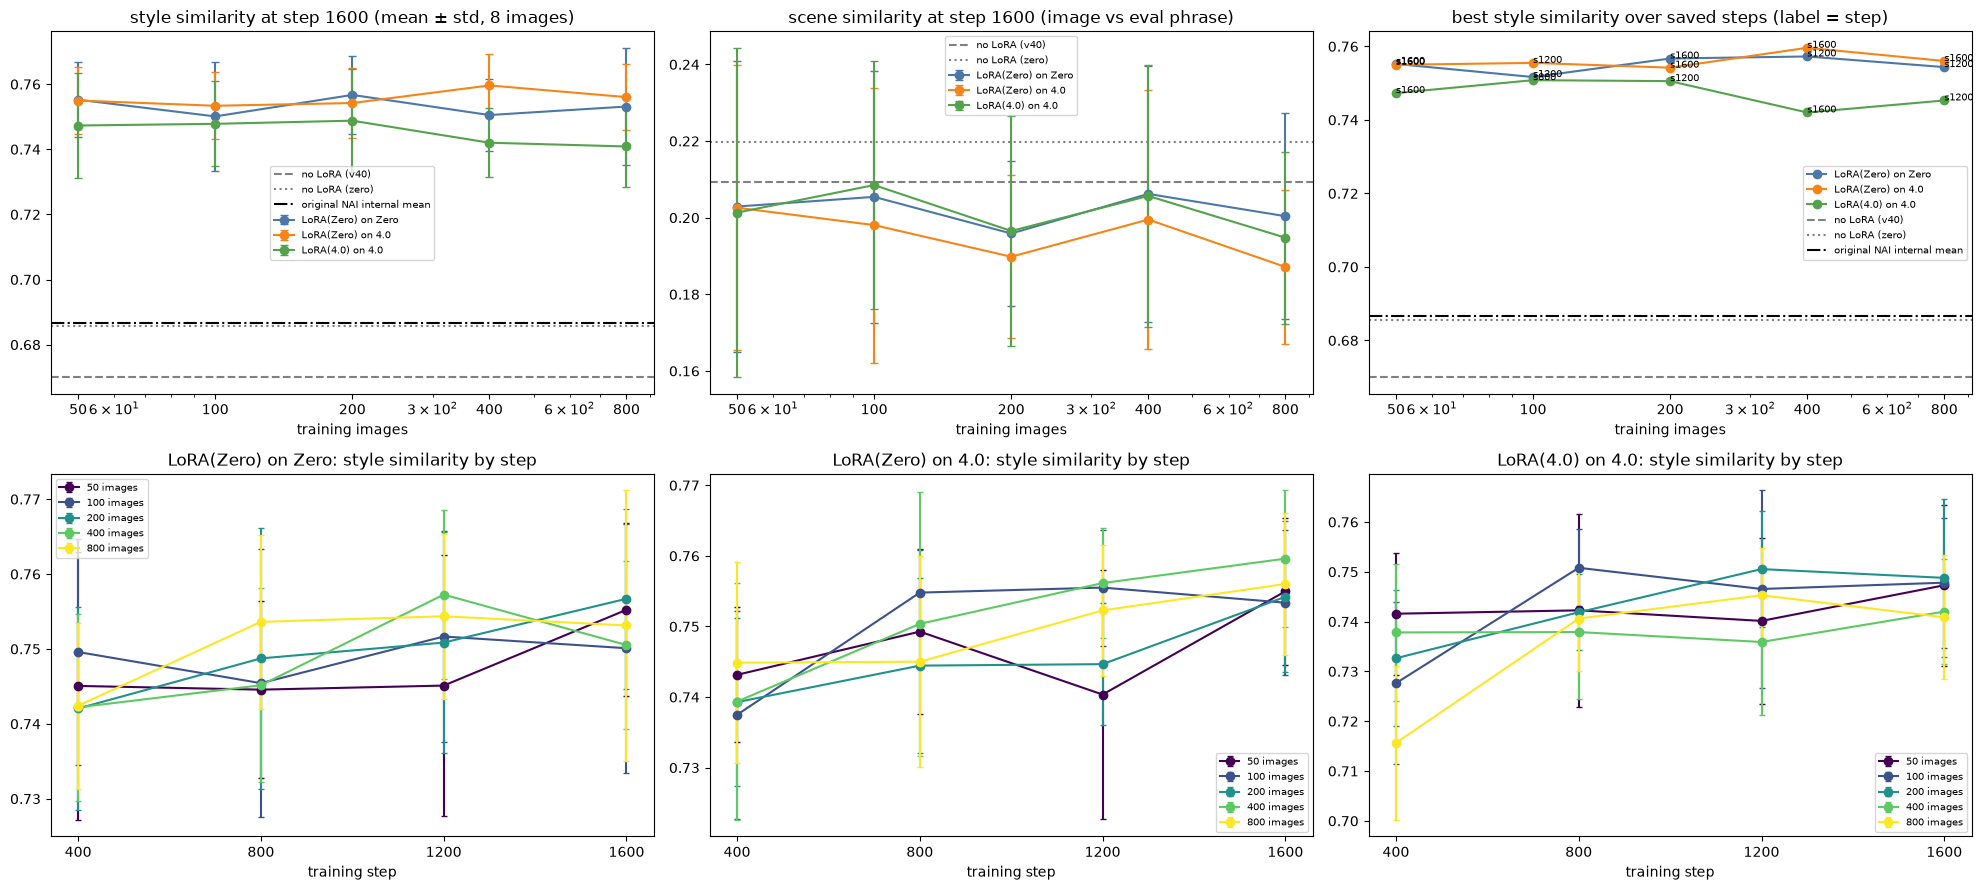

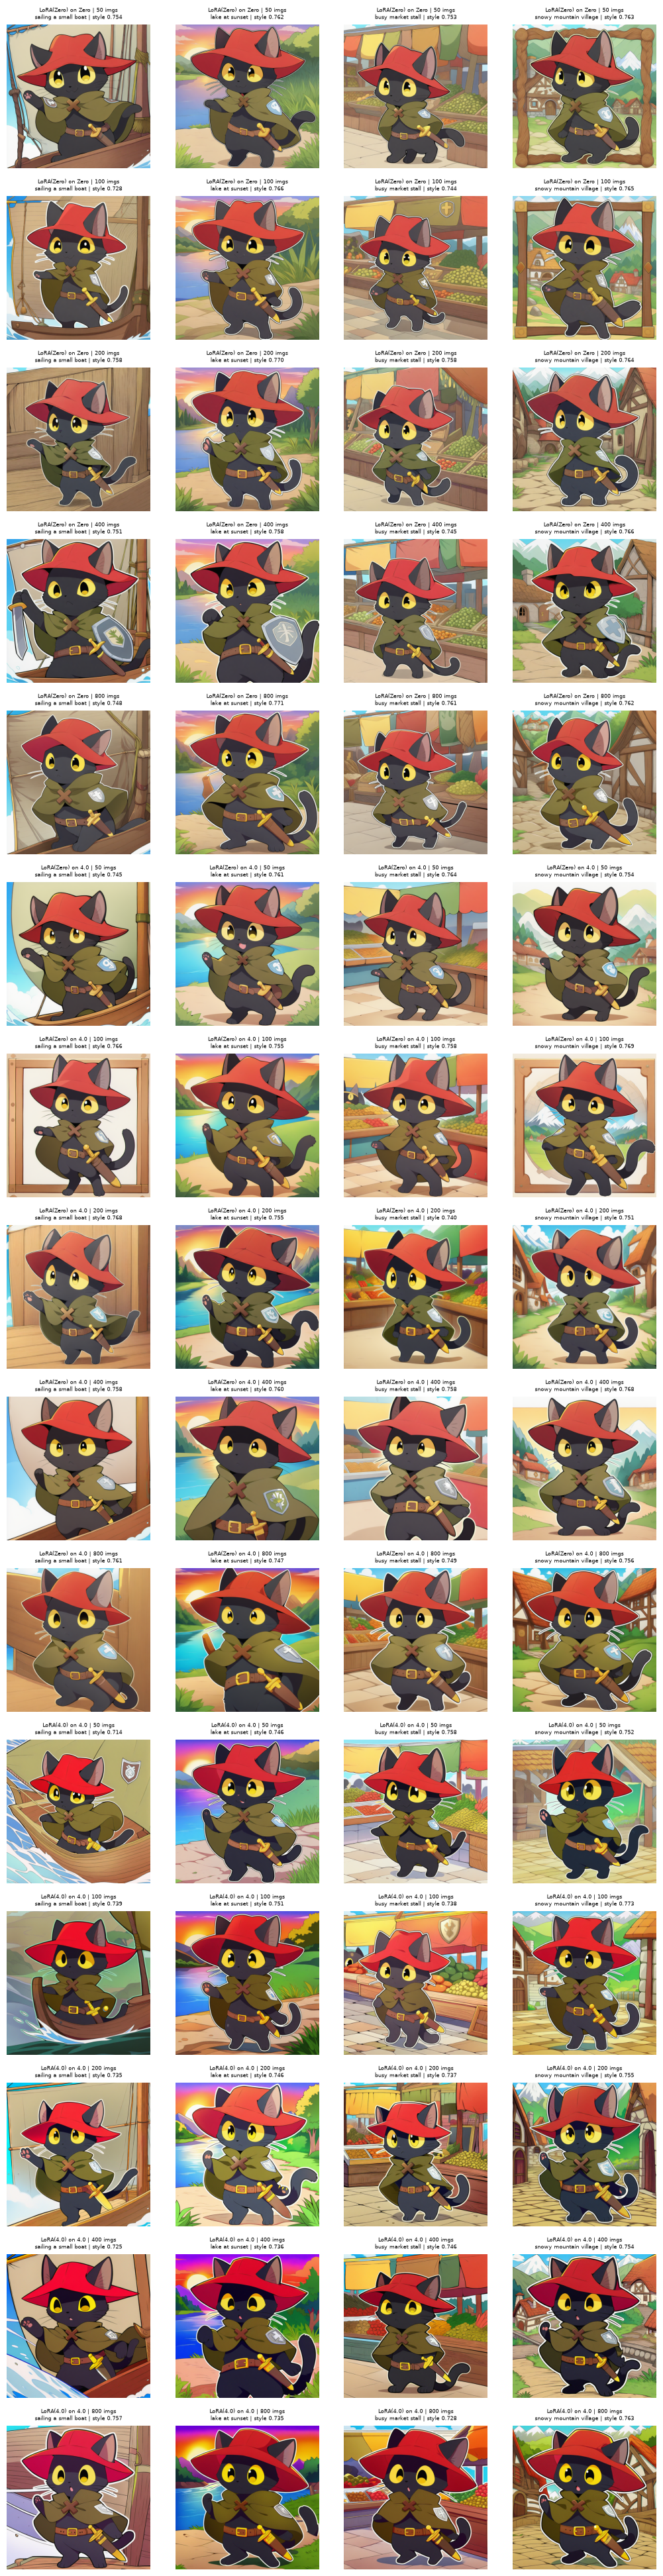

In [7]:
sizes = SWEEP_SIZES + [FULL_SIZE]
labels = [APPLY_NAME[(a, t)] for a, t in APPLY if t in TRAIN_CKPTS]
colors = dict(zip(labels, ['#4C78A8', '#F58518', '#54A24B']))
base = summary[summary.train_ckpt == ''].set_index('apply')
last = summary[summary.step == max(EVAL_STEPS)]

fig, axes = plt.subplots(2, 3, figsize=(20, 9))
# 위: 마지막 스텝 기준 장수별 그림체·장면 점수, 학습 스텝별 최고 그림체 점수
for lab in labels:
    s = last[last.label == lab].sort_values('size')
    axes[0, 0].errorbar(s['size'], s.style_sim, yerr=s.style_std, marker='o', capsize=3, color=colors[lab], label=lab)
    axes[0, 1].errorbar(s['size'], s.scene_sim, yerr=s.scene_std, marker='o', capsize=3, color=colors[lab], label=lab)
    b = summary[summary.label == lab].sort_values('style_sim').groupby('size').tail(1).sort_values('size')
    axes[0, 2].plot(b['size'], b.style_sim, marker='o', color=colors[lab], label=lab)
    for _, r in b.iterrows():
        axes[0, 2].annotate(f's{int(r.step)}', (r['size'], r.style_sim), fontsize=7)
for ax, col in [(axes[0, 0], 'style_sim'), (axes[0, 1], 'scene_sim'), (axes[0, 2], 'style_sim')]:
    for apply, ls in [('v40', '--'), ('zero', ':')]:
        if apply in base.index:
            ax.axhline(base.loc[apply, col], color='gray', linestyle=ls, label=f'no LoRA ({apply})')
    if col == 'style_sim':
        ax.axhline(orig_base, color='black', linestyle='-.', label='original NAI internal mean')
axes[0, 0].set_title(f'style similarity at step {max(EVAL_STEPS)} (mean ± std, 8 images)')
axes[0, 1].set_title(f'scene similarity at step {max(EVAL_STEPS)} (image vs eval phrase)')
axes[0, 2].set_title('best style similarity over saved steps (label = step)')
# 아래: 조합마다 학습 스텝별 그림체 점수 (선 = 장수)
cmap = plt.get_cmap('viridis')
for ax, lab in zip(axes[1], labels):
    for k, size in enumerate(sizes):
        s = summary[(summary.label == lab) & (summary['size'] == size)].sort_values('step')
        ax.errorbar(s.step, s.style_sim, yerr=s.style_std, marker='o', capsize=2, color=cmap(k / (len(sizes) - 1)),
                    label=f'{size} images')
    ax.set_xticks(EVAL_STEPS)
    ax.set_xlabel('training step')
    ax.set_title(f'{lab}: style similarity by step')
for ax in axes[0]:
    ax.set_xscale('log')
    ax.set_xticks(sizes, [str(s) for s in sizes])
    ax.set_xlabel('training images')
for ax in axes.flat:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT_DIR / 'sweep_scores.png', dpi=90)
plt.show()

# 이미지 그리드 (seed 0, 마지막 스텝): 행 = 조합 × 장수, 열 = 평가 문구
rows = [(lab, size) for lab in labels for size in sizes]
fig, axes = plt.subplots(len(rows), len(EVAL_PHRASES), figsize=(2.6 * len(EVAL_PHRASES), 2.6 * len(rows)), squeeze=False)
for r, (lab, size) in enumerate(rows):
    for j, ph in enumerate(EVAL_PHRASES):
        ax = axes[r, j]
        ax.axis('off')
        hit = ev[(ev.label == lab) & (ev['size'] == size) & (ev.step == max(EVAL_STEPS)) & (ev.phrase == ph) & (ev.seed == 0)]
        if len(hit):
            h = hit.iloc[0]
            ax.imshow(Image.open(h.path).convert('RGB'))
            ax.set_title(f'{lab} | {size} imgs\n{ph} | style {h.style_sim:.3f}', fontsize=6)
plt.tight_layout()
plt.savefig(OUT_DIR / 'sweep_grid.png', dpi=60)
plt.show()